In [3]:
import uproot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize

In [61]:
data = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/highHCalSFs_data.root")
#data = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/highHCalSFs_shifteddata.root")
mc = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/highHCalSFs_mc.root")

In [62]:
events_data=data["demo"]["allEvents"]["treeVariables"]
events_mc=mc["demo"]["allEvents"]["treeVariables"]
data_arr = events_data.arrays(library="pd")
mc_arr = events_mc.arrays(library="pd")

In [63]:
missingHits_data = data_arr[(data_arr["depthsFound"]-data_arr["hitsOverThresh"])>2]
print(sum(data_arr["depthsFound"]-data_arr["hitsOverThresh"]))

84045


In [64]:
etaCut = 0.016
phiCut = 0.004

etaEdgeCond = abs(missingHits_data["cellDetaDepth_0"])<etaCut
phiEdgeCond = abs(missingHits_data["cellDphiDepth_0"])<phiCut

for depth in range(1,7):
    etaEdgeCond = (etaEdgeCond) | (abs(missingHits_data["cellDetaDepth_"+str(depth)])<etaCut)                                   
    phiEdgeCond = (phiEdgeCond) | (abs(missingHits_data["cellDphiDepth_"+str(depth)])<phiCut)

In [65]:
etaEdgeEvents_data = missingHits_data[etaEdgeCond & ~phiEdgeCond]
phiEdgeEvents_data = missingHits_data[phiEdgeCond & ~etaEdgeCond]

In [66]:
etaHitCount = [0] * etaEdgeEvents_data.shape[0]
recoveredEtaHits = [0,0]
for depth in range(7):
    for idx, energy in enumerate(etaEdgeEvents_data["neighborEtahitEnergiesDepth"+str(depth)]):
        if energy > 0.2:
            etaHitCount[idx] = etaHitCount[idx]+1
    for idx, energy in enumerate(etaEdgeEvents_data["hitEnergiesDepth"+str(depth)]):
        if energy < 0.2: 
            neighborEnergy = etaEdgeEvents_data["neighborEtahitEnergiesDepth"+str(depth)].iloc[idx]
            if neighborEnergy>0.2:
                recoveredEtaHits[1] = recoveredEtaHits[1]+1
            else:
                recoveredEtaHits[0] = recoveredEtaHits[0]+1
            
etaMissingHitCount = etaEdgeEvents_data["depthsFound"]-etaHitCount
print(recoveredEtaHits[1]/sum(recoveredEtaHits))

0.5588958158494185


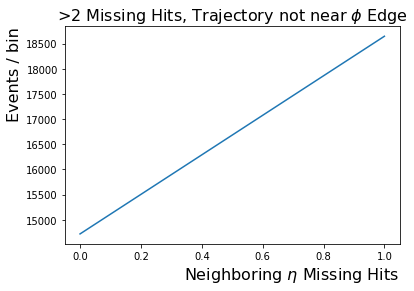

In [67]:
plt.plot([0,1],recoveredEtaHits)
plt.xlabel("Neighboring $\eta$ Missing Hits", loc='right', fontsize=16)
plt.ylabel("Events / bin", loc='top', fontsize=16)
plt.title(">2 Missing Hits, Trajectory not near $\phi$ Edge",fontsize=16)
#plt.ylim([0.0004,40])
plt.grid(False)    
plt.savefig("etaEdgeEvents_NeighborEnergy.pdf")

In [127]:
phiEdgeMin = [1] * phiEdgeEvents_data.shape[0]
for depth in range(7):
   for idx, dphi in enumerate(phiEdgeEvents_data["cellDphiDepth_"+str(depth)]):
      if abs(dphi) < abs(phiEdgeMin[idx]) and dphi>-0.9:
         phiEdgeMin[idx]=dphi
etaEdgeMin = [1] * etaEdgeEvents_data.shape[0]
for depth in range(7):
   for idx, deta in enumerate(etaEdgeEvents_data["cellDetaDepth_"+str(depth)]):
      if abs(deta) < abs(etaEdgeMin[idx]) and deta>-0.9:
         etaEdgeMin[idx]=deta
allPhiEdgeMin = [1] * data_arr.shape[0]
for depth in range(7):
   for idx, dphi in enumerate(data_arr["cellDphiDepth_"+str(depth)]):
      if abs(dphi) < abs(allPhiEdgeMin[idx]) and dphi>-0.9:
         allPhiEdgeMin[idx]=dphi
allEtaEdgeMin = [1] * data_arr.shape[0]
for depth in range(7):
   for idx, deta in enumerate(data_arr["cellDetaDepth_"+str(depth)]):
      if abs(deta) < abs(allEtaEdgeMin[idx]) and deta>-0.9:
         allEtaEdgeMin[idx]=deta
mcPhiEdgeMin = [1] * mc_arr.shape[0]
for depth in range(7):
   for idx, dphi in enumerate(mc_arr["cellDphiDepth_"+str(depth)]):
      if abs(dphi) < abs(mcPhiEdgeMin[idx]) and dphi>-0.9:
         mcPhiEdgeMin[idx]=dphi
mcEtaEdgeMin = [1] * mc_arr.shape[0]
for depth in range(7):
   for idx, deta in enumerate(mc_arr["cellDetaDepth_"+str(depth)]):
      if abs(deta) < abs(mcEtaEdgeMin[idx]) and deta>-0.9:
         mcEtaEdgeMin[idx]=deta

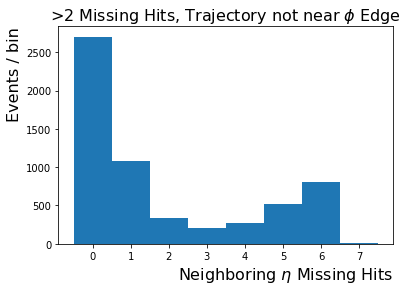

In [69]:
plt.hist(etaMissingHitCount, bins=[binx-0.5 for binx in range(0,9)])
plt.xlabel("Neighboring $\eta$ Missing Hits", loc='right', fontsize=16)
plt.ylabel("Events / bin", loc='top', fontsize=16)
plt.title(">2 Missing Hits, Trajectory not near $\phi$ Edge",fontsize=16)
#plt.ylim([0.0004,40])
plt.grid(False)    
plt.savefig("etaEdgeEvents_NeighborEnergy.pdf")


0.2824754901960784


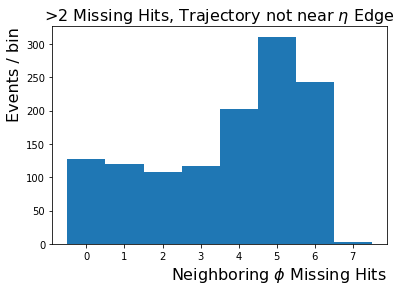

In [70]:
phiHitCount = [0] * phiEdgeEvents_data.shape[0]
recoveredPhiHits = [0,0]
for depth in range(7):
    for idx, energy in enumerate(phiEdgeEvents_data["neighborPHihitEnergiesDepth"+str(depth)]):
        if energy > 0.2:
            phiHitCount[idx] = phiHitCount[idx]+1
    for idx, energy in enumerate(etaEdgeEvents_data["hitEnergiesDepth"+str(depth)]):
        if energy > 0.2: 
            neighborEnergy = etaEdgeEvents_data["neighborPHihitEnergiesDepth"+str(depth)].iloc[idx]
            if neighborEnergy>0.2:
                recoveredPhiHits[1] = recoveredPhiHits[1]+1
            else:
                recoveredPhiHits[0] = recoveredPhiHits[0]+1        
print(recoveredPhiHits[1]/sum(recoveredPhiHits))
missingPhiCount = phiEdgeEvents_data["depthsFound"]-phiHitCount
plt.hist(missingPhiCount, bins=[binx-0.5 for binx in range(0,9)])
#plt.ylim([0.0004,40])
plt.grid(False)    
plt.xlabel("Neighboring $\phi$ Missing Hits", loc='right', fontsize=16)
plt.ylabel("Events / bin", loc='top', fontsize=16)
plt.title(">2 Missing Hits, Trajectory not near $\eta$ Edge",fontsize=16)
plt.savefig("phiEdgeEvents_NeighborEnergy.pdf")

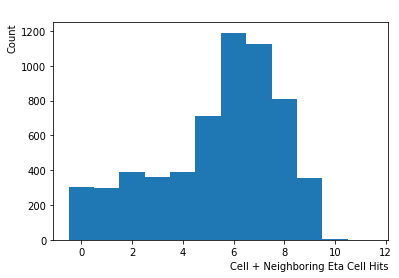

In [71]:
totalHitCount = etaHitCount + etaEdgeEvents_data["hitsOverThresh"]
plt.hist(totalHitCount, bins=[binx-0.5 for binx in range(0,13)])
plt.xlabel("Cell + Neighboring Eta Cell Hits", loc='right')
plt.ylabel("Count", loc='top')
#plt.ylim([0.0004,40])
plt.grid(False)    
plt.title(" ")
plt.savefig("etaEdgeTotalEvents_NeighborEnergy.pdf")

In [128]:
etaEdgeEventsData = etaEdgeEvents_data.copy()
etaEdgeEventsData["neighborCellCounts"] = etaHitCount
etaEdgeEventsData["minDEta"] = etaEdgeMin
phiEdgeEventsData = phiEdgeEvents_data.copy()
phiEdgeEventsData["neighborCellCounts"] = phiHitCount
phiEdgeEventsData["minDPhi"] = phiEdgeMin
eventsData = data_arr.copy()
eventsData["minDEta"] = allEtaEdgeMin
eventsData["minDPhi"] = allPhiEdgeMin
eventsMC = mc_arr.copy()
eventsMC["minDEta"] = mcEtaEdgeMin
eventsMC["minDPhi"] = mcPhiEdgeMin

In [126]:
etaEdgeCond = ((eventsData["eta"]>0)&(eventsData["minDEta"]<0.002)&(eventsData["minDEta"]>-0.016))|((eventsData["eta"]<0)&(eventsData["minDEta"]>-0.002)&(eventsData["minDEta"]<0.016))
phiEdgeCond = ((abs(eventsData["phi"])>1.5)&(eventsData["minDPhi"]<0.001)&(eventsData["minDPhi"]>-0.004))|((abs(eventsData["phi"])<1.5)&(eventsData["minDPhi"]<0.004)&(eventsData["minDPhi"]>-0.001))
oldEdgeCond = abs(eventsData["minDEta"])<0.016
oldPhiCond = abs(eventsData["minDPhi"])<0.004
print(len(eventsData))
print(len(eventsData[etaEdgeCond|phiEdgeCond])/len(eventsData))
print(len(eventsData[oldEdgeCond|oldPhiCond])/len(eventsData))

121610
0.24105747882575446
0.3779212235835869


In [129]:
mcEtaEdgeCond = ((eventsMC["eta"]>0)&(eventsMC["minDEta"]<0.002)&(eventsMC["minDEta"]>-0.016))|((eventsMC["eta"]<0)&(eventsMC["minDEta"]>-0.002)&(eventsMC["minDEta"]<0.016))
mcPhiEdgeCond = ((abs(eventsMC["phi"])>1.5)&(eventsMC["minDPhi"]<0.001)&(eventsMC["minDPhi"]>-0.004))|((abs(eventsMC["phi"])<1.5)&(eventsMC["minDPhi"]<0.004)&(eventsMC["minDPhi"]>-0.001))

In [74]:
recoveredPosEtaEdgeEventsData = etaEdgeEventsData[(etaEdgeEventsData["neighborCellCounts"]>4) & (etaEdgeEventsData["eta"]>0)]
recoveredNegEtaEdgeEventsData = etaEdgeEventsData[(etaEdgeEventsData["neighborCellCounts"]>4) & (etaEdgeEventsData["eta"]<0)]
failedPosEtaEdgeEventsData = etaEdgeEventsData[(etaEdgeEventsData["neighborCellCounts"]<3) & (etaEdgeEventsData["eta"]>0)]
failedNegEtaEdgeEventsData = etaEdgeEventsData[(etaEdgeEventsData["neighborCellCounts"]<3) & (etaEdgeEventsData["eta"]<0)]
recoveredPosPhiEdgeEventsData = phiEdgeEventsData[(phiEdgeEventsData["eta"]>0)&(phiEdgeEventsData["neighborCellCounts"]>4)]
recoveredNegPhiEdgeEventsData = phiEdgeEventsData[phiEdgeEventsData["eta"]<0]
posEtaEdgeEventsData = etaEdgeEventsData[(etaEdgeEventsData["eta"]>0)]
negEtaEdgeEventsData = etaEdgeEventsData[(etaEdgeEventsData["eta"]<0)]
posPhiEdgeEventsData = phiEdgeEventsData[(phiEdgeEventsData["eta"]>0)]
negPhiEdgeEventsData = phiEdgeEventsData[(phiEdgeEventsData["eta"]<0)]

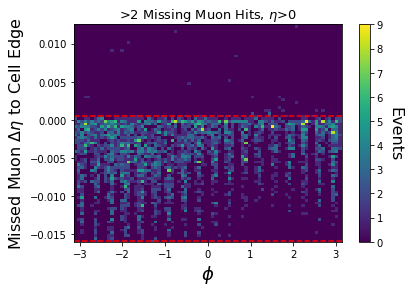

In [130]:
h = plt.hist2d(posEtaEdgeEventsData["phi"], posEtaEdgeEventsData["minDEta"], bins=80, range=None, density=None, weights=None)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('Missed Muon $\Delta\eta$ to Cell Edge', fontsize=16)
plt.title('>2 Missing Muon Hits, $\eta$>0',fontsize=13)
cbar = plt.colorbar(h[3])
cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
x_points = [-3.14,3.14]
y_points = [0.0005, 0.0005]
plt.plot(x_points, y_points, 'r',linestyle='dashed')
y_points_2 = [-0.01585,-0.01585]
plt.plot(x_points, y_points_2, 'r',linestyle='dashed')
plt.savefig("posEtaEdgeEventsData.pdf")
plt.show()

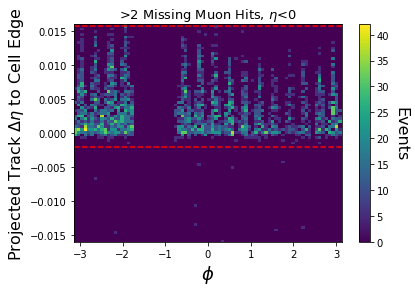

In [111]:
plt.hist2d(negEtaEdgeEventsData["phi"], negEtaEdgeEventsData["minDEta"], bins=80, range=[[-3.14,3.14],[-0.016,0.016]], density=None, weights=None)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('Projected Track $\Delta\eta$ to Cell Edge', fontsize=16)
plt.title('>2 Missing Muon Hits, $\eta$<0',fontsize=13)
cbar = plt.colorbar(h[3])
cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
x_points = [-3.14,3.14]
y_points = [-0.002, -0.002]
plt.plot(x_points, y_points, 'r',linestyle='dashed')
y_points_2 = [0.01583,0.01583]
plt.plot(x_points, y_points_2, 'r',linestyle='dashed')
plt.savefig("recoveredNegEtaEdgeEventsData.pdf")

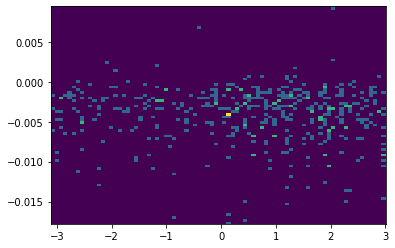

In [49]:
plt.hist2d(failedPosEtaEdgeEventsData["phi"], failedPosEtaEdgeEventsData["cellDetaDepth_0"], bins=80, range=None, density=None, weights=None)
plt.savefig("failedPosEtaEdgeEventsData.pdf")

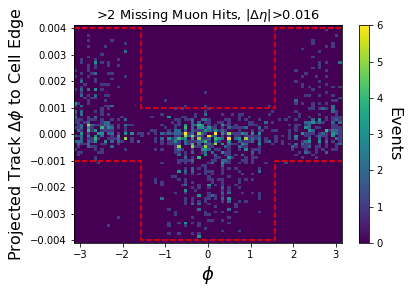

In [81]:
h = plt.hist2d(phiEdgeEventsData["phi"], phiEdgeEventsData["minDPhi"], bins=80, range=[[-3.14,3.14],[-0.0041,0.0041]], density=None, weights=None)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('Projected Track $\Delta\phi$ to Cell Edge', fontsize=16)
plt.title('>2 Missing Muon Hits, |$\Delta\eta$|>0.016',fontsize=13)
x_points = [-3.14, -3.14/2., -3.14/2.,3.14/2.,3.14/2.,3.14]
y_points = [-0.001, -0.001, -0.004,-0.004,-0.001,-0.001]
plt.plot(x_points, y_points, 'r',linestyle='dashed')
y_points_2 = [0.004, 0.004, 0.001,0.001,0.004,0.004]
plt.plot(x_points, y_points_2, 'r',linestyle='dashed')
cbar = plt.colorbar(h[3])
cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
plt.savefig("posPhiEdgeEventsData.pdf")

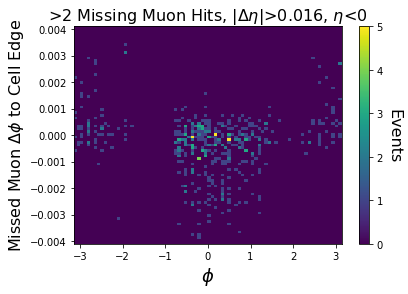

In [82]:
h = plt.hist2d(negPhiEdgeEventsData["phi"], negPhiEdgeEventsData["minDPhi"], bins=80, range=[[-3.14,3.14],[-0.0041,0.0041]], density=None, weights=None)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('Missed Muon $\Delta\phi$ to Cell Edge', fontsize=16)
plt.title('>2 Missing Muon Hits, |$\Delta\eta$|>0.016, $\eta$<0',fontsize=16)
#x_points = [-3.14, -3.14/2., -3.14/2.,3.14/2.,3.14/2.,3.14]
#y_points = [-0.001, -0.001, -0.004,-0.004,-0.001,-0.001]
#plt.plot(x_points, y_points, 'r',linestyle='dashed')
#y_points_2 = [0.004, 0.004, 0.001,0.001,0.004,0.004]
#plt.plot(x_points, y_points_2, 'r',linestyle='dashed')
cbar = plt.colorbar(h[3])
cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
plt.savefig("negPhiEdgeEventsData.pdf")

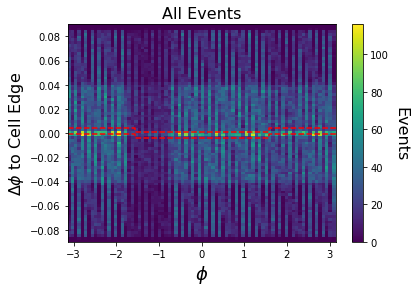

In [112]:
h = plt.hist2d(eventsData["phi"], eventsData["minDPhi"], bins=80, range=[[-3.14,3.14],[-0.09,0.09]], density=None, weights=None)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('$\Delta\phi$ to Cell Edge', fontsize=16)
plt.title('All Events',fontsize=16)
x_points = [-3.14, -3.14/2., -3.14/2.,3.14/2.,3.14/2.,3.14]
y_points = [-0.001, -0.001, -0.004,-0.004,-0.001,-0.001]
plt.plot(x_points, y_points, 'r',linestyle='dashed')
y_points_2 = [0.004, 0.004, 0.001,0.001,0.004,0.004]
plt.plot(x_points, y_points_2, 'r',linestyle='dashed')
cbar = plt.colorbar(h[3])
cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
plt.savefig("AllPhiEventsData.pdf")

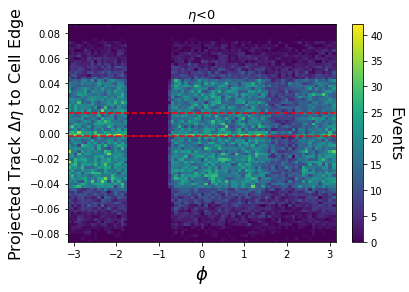

In [104]:
negEtaData = eventsData[eventsData["eta"]<0]
h = plt.hist2d(negEtaData["phi"], negEtaData["minDEta"], bins=80, range=None, density=None, weights=None)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('Projected Track $\Delta\eta$ to Cell Edge', fontsize=16)
plt.title('$\eta$<0',fontsize=13)
x_points = [-3.14,3.14]
y_points = [-0.002, -0.002]
plt.plot(x_points, y_points, 'r',linestyle='dashed')
y_points_2 = [0.016,0.016]
plt.plot(x_points, y_points_2, 'r',linestyle='dashed')
cbar = plt.colorbar(h[3])
cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
plt.show()

In [ ]:
plt.hist2d(phiEdgeEventsData["phi"], phiEdgeEventsData["cellDphiDepth_3"], bins=80, range=None, density=None, weights=None)
plt.savefig("recoveredNegPhiEdgeEventsData.pdf")


In [ ]:
plt.hist2d(missingHits_data["phi"], missingHits_data["cellDphiDepth_3"], bins=80, range=[[-3.14, 3.14], [-0.06, 0.06]], density=None, weights=None)
plt.savefig("recoveredPosPhiEdgeEventsData.pdf")


In [ ]:
phiHist, xbins, ybins = np.histogram2d(posPhiEdgeEventsData["phi"], posPhiEdgeEventsData["cellDphiDepth_3"], bins=40, range=None, density=None, weights=None)
ybinCenters = [(ybins[binx]+ybins[binx+1])/2. for binx in range(0,len(ybins)-1)]
xbinCenters = [(xbins[binx]+xbins[binx+1])/2. for binx in range(0,len(xbins)-1)]
for val in range(0,len(phiHist)):
    phiHist[val] = phiHist[val]*ybinCenters
phiProj = [sum(phiHist[val])/max(1,sum(abs(entry) > 0.001 for entry in phiHist[val])) for val in range(0,len(phiHist))]

In [ ]:
phiHist[0]

In [ ]:
def fit_sin(tt, yy):
    '''Fit sin to the input time sequence, and return fitting parameters "amp", "omega", "phase", "offset", "freq", "period" and "fitfunc"'''
    tt = np.array(tt)
    yy = np.array(yy)
    ff = np.fft.fftfreq(len(tt), (tt[1]-tt[0]))   # assume uniform spacing
    Fyy = abs(np.fft.fft(yy))
    guess_freq = abs(ff[np.argmax(Fyy[1:])+1])   # excluding the zero frequency "peak", which is related to offset
    guess_amp = np.std(yy) * 2.**0.5
    guess_offset = np.mean(yy)
    guess = np.array([guess_amp, 2.*np.pi*guess_freq, 0., guess_offset])

    def sinfunc(t, A, w, p, c):  return A * np.sin(w*t + p) + c
    popt, pcov = scipy.optimize.curve_fit(sinfunc, tt, yy, p0=guess)
    A, w, p, c = popt
    f = w/(2.*np.pi)
    fitfunc = lambda t: float(A) * np.sin(w*t + p) + c
    return {"amp": A, "omega": w, "phase": p, "offset": c, "freq": f, "period": 1./f, "fitfunc": fitfunc, "maxcov": np.max(pcov), "rawres": (guess,popt,pcov)}

In [ ]:
res = fit_sin(xbinCenters, phiProj)
plt.plot(xbinCenters, phiProj, 'ok')
plt.plot(xbinCenters, res["fitfunc"](np.array(xbinCenters)), "r-", label="Cosine Fit", linewidth=2)
plt.xlabel('$\phi$', fontsize=18)
plt.ylabel('Missed Muon Average $\Delta\phi$', fontsize=16)
plt.title('>2 Missing Muon Hits, $\eta$>0', fontsize=16)
plt.show()
print("Phase is " + str(res["phase"]))

In [ ]:
amplitudes = []
for depth in range(7):
   cutMissing = posPhiEdgeEventsData[posPhiEdgeEventsData["cellDphiDepth_"+str(depth)]>-0.9]
   binnedPhiHist, x, y = np.histogram2d(cutMissing["phi"], cutMissing["cellDphiDepth_"+str(depth)], bins=40, range=None, density=None, weights=None)
   ybinCenters = [(y[binx]+y[binx+1])/2. for binx in range(0,len(y)-1)]
   xbinCenters = [(x[binx]+x[binx+1])/2. for binx in range(0,len(x)-1)]
   for val in range(0,len(phiHist)):
      binnedPhiHist[val] = binnedPhiHist[val]*ybinCenters
   binnedPhiProj = [sum(binnedPhiHist[val])/max(1,sum(abs(entry) > 0.001 for entry in binnedPhiHist[val])) for val in range(0,len(binnedPhiHist))]
   res = fit_sin(xbinCenters, binnedPhiProj)
   plt.plot(xbinCenters, binnedPhiProj, 'ok')
   plt.plot(xbinCenters, res["fitfunc"](np.array(xbinCenters)), "r-", label="Cosine Fit", linewidth=2)
   plt.xlabel('$\phi$', fontsize=18)
   plt.ylabel('Missed Muon Average $\Delta\phi$', fontsize=16)
   plt.title('>2 Missing Muon Hits, $\eta$<0, Depth '+str(depth), fontsize=16)
   plt.show()
   amplitudes.append(res["amp"])
   print("Amplitude is: "+str(res["amp"]))

In [ ]:
plt.plot([i for i in range(7)], amplitudes, "ok")
plt.xlabel('Depth', fontsize=18)
plt.ylabel('Fit Amplitude', fontsize=16)
plt.title('>2 Missing Muon Hits, $\eta$<0', fontsize=16)
plt.show()

In [30]:
negEndcapData = data_arr[(data_arr["eta"]<0)]
posEndcapData = data_arr[(data_arr["eta"]>0)]

In [ ]:
yshiftmissingHits = []
for yshift in range(-50,50):
    yshiftcm = yshift/10.
    shiftHitCounts = [0] * posEndcapData.shape[0]
    for depth in range(7):
        for idx, energy in enumerate(posEndcapData["hitEnergiesDepth"+str(depth)]):
            if(yshiftcm>0):
                if((posEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]>0)&(posEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]<=yshiftcm)):
                    if(posEndcapData["yShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1        
            else:
                if((posEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]<0)&(posEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]>=yshiftcm)):
                    if(posEndcapData["yShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1  

    print(yshiftcm, sum(posEndcapData["depthsFound"]-shiftHitCounts))
    yshiftmissingHits.append(sum(posEndcapData["depthsFound"]-shiftHitCounts))
print(yshiftmissingHits)

In [ ]:
plt.plot([xbin/10. for xbin in range(-50,50)], yshiftmissingHits, 'sk')
plt.xlabel('Transient Track $\Delta$y Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$>0', fontsize=16)
plt.show()

In [ ]:
negyshiftmissingHits = []
for yshift in range(-50,50):
    yshiftcm = yshift/10.
    shiftHitCounts = [0] * negEndcapData.shape[0]
    for depth in range(7):
        for idx, energy in enumerate(negEndcapData["hitEnergiesDepth"+str(depth)]):
            if(yshiftcm>0):
                if((negEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]>0)&(negEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]<=yshiftcm)):
                    if(negEndcapData["yShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1        
            else:
                if((negEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]<0)&(negEndcapData["yShiftsdepth_"+str(depth)].iloc[idx]>=yshiftcm)):
                    if(negEndcapData["yShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1  
    negyshiftmissingHits.append(sum(negEndcapData["depthsFound"]-shiftHitCounts))
print(negyshiftmissingHits)

In [ ]:
plt.plot([xbin/10. for xbin in range(-50,50)], negyshiftmissingHits, 'sk')
plt.xlabel('Transient Track $\Delta$y Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$<0', fontsize=16)
plt.show()

In [ ]:
posxshiftmissingHits = []
for xshift in range(-50,50):
    xshiftcm = xshift/10.
    shiftHitCounts = [0] * posEndcapData.shape[0]
    for depth in range(7):
        for idx, energy in enumerate(posEndcapData["hitEnergiesDepth"+str(depth)]):
            if(xshiftcm>0):
                if((posEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]>0)&(posEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]<=xshiftcm)):
                    if(posEndcapData["xShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1        
            else:
                if((posEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]<0)&(posEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]>=xshiftcm)):
                    if(posEndcapData["xShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1  

    print(xshiftcm, sum(posEndcapData["depthsFound"]-shiftHitCounts))
    posxshiftmissingHits.append(sum(posEndcapData["depthsFound"]-shiftHitCounts))

In [ ]:
negxshiftmissingHits = []
for xshift in range(-50,50):
    xshiftcm = xshift/10.
    shiftHitCounts = [0] * negEndcapData.shape[0]
    for depth in range(7):
        for idx, energy in enumerate(negEndcapData["hitEnergiesDepth"+str(depth)]):
            if(xshiftcm>0):
                if((negEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]>0)&(negEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]<=xshiftcm)):
                    if(negEndcapData["xShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1        
            else:
                if((negEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]<0)&(negEndcapData["xShiftsdepth_"+str(depth)].iloc[idx]>=xshiftcm)):
                    if(negEndcapData["xShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1  

    print(xshiftcm, sum(negEndcapData["depthsFound"]-shiftHitCounts))
    negxshiftmissingHits.append(sum(negEndcapData["depthsFound"]-shiftHitCounts))

In [ ]:
plt.plot([xbin/10. for xbin in range(-50,50)], yshiftmissingHits, 'ok')
plt.xlabel('Transient Track $\Delta$y Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$>0', fontsize=16)
plt.show()
plt.plot([xbin/10. for xbin in range(-50,50)], negyshiftmissingHits, 'ok')
plt.xlabel('Transient Track $\Delta$y Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$<0', fontsize=16)
plt.show()
plt.plot([xbin/10. for xbin in range(-50,50)], posxshiftmissingHits, 'sk')
plt.xlabel('Transient Track $\Delta$x Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$>0', fontsize=16)
plt.show()
plt.plot([xbin/10. for xbin in range(-50,50)], negxshiftmissingHits, 'sk')
plt.xlabel('Transient Track $\Delta$x Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$<0', fontsize=16)
plt.show()

In [31]:
negzshiftmissingHits = []
for zshift in range(-50,50):
    zshiftcm = zshift/5.
    shiftHitCounts = [0] * negEndcapData.shape[0]
    for depth in range(7):
        for idx, energy in enumerate(negEndcapData["hitEnergiesDepth"+str(depth)]):
            if(zshiftcm>0):
                if((negEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]>0)&(negEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]<=zshiftcm)):
                    if(negEndcapData["zShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1        
            else:
                if((negEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]<0)&(negEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]>=zshiftcm)):
                    if(negEndcapData["zShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1  

    print(zshiftcm, sum(negEndcapData["depthsFound"]-shiftHitCounts))
    negzshiftmissingHits.append(sum(negEndcapData["depthsFound"]-shiftHitCounts))

-10.0 18103
-9.8 17604
-9.6 17173
-9.4 16755
-9.2 16359
-9.0 15981
-8.8 15614
-8.6 15310
-8.4 15015
-8.2 14694
-8.0 14416
-7.8 14160
-7.6 13961
-7.4 13796
-7.2 13590
-7.0 13415
-6.8 13313
-6.6 13185
-6.4 13135
-6.2 13066
-6.0 12983
-5.8 12991
-5.6 12982
-5.4 12948
-5.2 12974
-5.0 12974
-4.8 12965
-4.6 12949
-4.4 12937
-4.2 12934
-4.0 12924
-3.8 12916
-3.6 12920
-3.4 12937
-3.2 12936
-3.0 12936
-2.8 12948
-2.6 12957
-2.4 12965
-2.2 12992
-2.0 13011
-1.8 13037
-1.6 13063
-1.4 13086
-1.2 13100
-1.0 13130
-0.8 13165
-0.6 13208
-0.4 13243
-0.2 13296
0.0 13342
0.2 13032
0.4 13260
0.6 13510
0.8 13758
1.0 14044
1.2 14326
1.4 14481
1.6 14766
1.8 15078
2.0 15370
2.2 15676
2.4 15977
2.6 16325
2.8 16675
3.0 17011
3.2 17315
3.4 17652
3.6 17948
3.8 18309
4.0 18646
4.2 18989
4.4 19508
4.6 19853
4.8 20193
5.0 20520
5.2 20882
5.4 21196
5.6 21535
5.8 21884
6.0 22201
6.2 22569
6.4 22912
6.6 23269
6.8 23577
7.0 23918
7.2 24302
7.4 24642
7.6 24989
7.8 25330
8.0 25674
8.2 25983
8.4 26324
8.6 26698
8.8 27038

In [34]:
poszshiftmissingHits = []
for zshift in range(-50,50):
    zshiftcm = zshift/5.
    shiftHitCounts = [0] * posEndcapData.shape[0]
    for depth in range(7):
        for idx, energy in enumerate(posEndcapData["hitEnergiesDepth"+str(depth)]):
            if(zshiftcm>0):
                if((posEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]>0)&(posEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]<=zshiftcm)):
                    if(posEndcapData["zShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1        
            else:
                if((posEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]<0)&(posEndcapData["zShiftsdepth_"+str(depth)].iloc[idx]>=zshiftcm)):
                    if(posEndcapData["zShiftEnergydepth_"+str(depth)].iloc[idx]>-0.8):
                        shiftHitCounts[idx] = shiftHitCounts[idx]+1
                elif(energy>0.2):
                    shiftHitCounts[idx] = shiftHitCounts[idx]+1  

    print(zshiftcm, sum(posEndcapData["depthsFound"]-shiftHitCounts))
    poszshiftmissingHits.append(sum(posEndcapData["depthsFound"]-shiftHitCounts))

-10.0 34944
-9.8 34518
-9.6 34118
-9.4 33688
-9.2 33256
-9.0 32850
-8.8 32417
-8.6 31968
-8.4 31526
-8.2 31103
-8.0 30710
-7.8 30218
-7.6 29812
-7.4 29408
-7.2 28964
-7.0 28577
-6.8 28198
-6.6 27799
-6.4 27357
-6.2 26962
-6.0 26542
-5.8 26144
-5.6 25730
-5.4 25317
-5.2 24910
-5.0 24480
-4.8 24051
-4.6 23639
-4.4 23244
-4.2 22662
-4.0 22262
-3.8 21876
-3.6 21453
-3.4 21085
-3.2 20708
-3.0 20288
-2.8 19893
-2.6 19504
-2.4 19118
-2.2 18709
-2.0 18326
-1.8 17904
-1.6 17488
-1.4 17100
-1.2 16908
-1.0 16592
-0.8 16275
-0.6 16027
-0.4 15862
-0.2 15765
0.0 15752
0.2 15077
0.4 15050
0.6 15020
0.8 14988
1.0 14953
1.2 14928
1.4 14920
1.6 14892
1.8 14861
2.0 14821
2.2 14785
2.4 14764
2.6 14736
2.8 14709
3.0 14696
3.2 14701
3.4 14706
3.6 14699
3.8 14691
4.0 14699
4.2 14661
4.4 14542
4.6 14495
4.8 14432
5.0 14372
5.2 14337
5.4 14373
5.6 14430
5.8 14461
6.0 14537
6.2 14626
6.4 14751
6.6 14937
6.8 15137
7.0 15300
7.2 15510
7.4 15738
7.6 16026
7.8 16309
8.0 16679
8.2 17055
8.4 17404
8.6 17802
8.8 18314

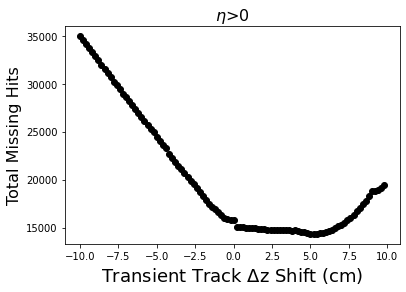

In [35]:
plt.plot([zbin/5. for zbin in range(-50,50)], poszshiftmissingHits, 'ok')
plt.xlabel('Transient Track $\Delta$z Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$>0', fontsize=16)
plt.show()

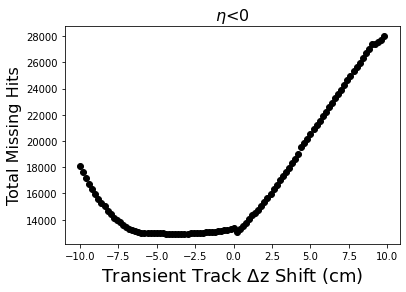

In [32]:
plt.plot([zbin/5. for zbin in range(-50,50)], negzshiftmissingHits, 'ok')
plt.xlabel('Transient Track $\Delta$z Shift (cm)', fontsize=18)
plt.ylabel('Total Missing Hits', fontsize=16)
plt.title('$\eta$<0', fontsize=16)
plt.show()